## 0. Configuration

In [ ]:
from logging import config


QUICK = False                         
RUN_S1, RUN_S2 = True, True           

SEEDS = [0] if QUICK else [0, 1, 2]   
K_FOLDS, SPLIT_SEED = 5, 0            

CFG = dict(
    backbone="vit_base_patch14_dinov2.lvd142m",   
    weights_file=None,        
    pretrained=True,
    cache_size=256, crop=224, lora_r=8,
    bs=16, eval_bs=64, lr_lora=5e-4, lr_head=1e-3, wd=1e-4,
    legacy_epochs=4 if QUICK else 20, legacy_patience=5,
    epochs=4 if QUICK else 30, patience=6,
    kd_lambda=1.0, fd_alpha=1.0, fd_beta=5.0,              
    wise_alpha=0.5, ct_eps=0.0,
    min_pos=5, n_boot=50 if QUICK else 300,                 
    alphas=(0.05, 0.10), ltt_delta=0.10,                    
    s1_epochs=2 if QUICK else 15,                           
    shape_dup_thr=5,                                        
    s2_backbone="vit_large_patch16_224",                    
    s2_weights=str(config.RETFOUND_WEIGHTS),
    s2_epochs=2 if QUICK else 20, s2_bs=16, s2_grad_ckpt=True,   
)
BASES = ["FT", "WiSE", "OE"]              
S2_METHODS = ["New", "New-FD"]           
OTHER_04 = ["FD", "CURE2", "OPC-noCT"]   
import numpy as _np; GRID = _np.linspace(-8, 8, 801)   

## 1. Setup

In [ ]:
import json, sys, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config, audit, cure, cv, crc, frontier, certify, backbones

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = config.OUTPUT_DIR
CACHE, CKPT, RES = OUT / "cache", OUT / "checkpoints", OUT / "results"
for d in (CACHE, CKPT, RES):
    d.mkdir(parents=True, exist_ok=True)
CV04 = RES / ("cv_quick" if QUICK else "cv")        
RAW = RES / ("cv07_quick" if QUICK else "cv07")     
S2DIR = RES / ("s2_07_quick" if QUICK else "s2_07")
for d in (RAW, S2DIR):
    d.mkdir(parents=True, exist_ok=True)
assert (CV04 / "folds.csv").exists(), f"Run notebook 04 first: {CV04 / 'folds.csv'} not found"
if RUN_S2:
    assert CFG["s2_weights"] is None or Path(CFG["s2_weights"]).exists(), (
        f"RETFound weights not found at {CFG['s2_weights']}: correct s2_weights, or set RUN_S2 = False")
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)

device: cuda NVIDIA GeForce RTX 4060
torch 2.11.0+cu128


## 2. Manifests and label spaces

In [ ]:
M = config.MANIFEST_DIR
man1 = {s: pd.read_csv(M / f"rfmid1_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
man2 = {s: pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
space = json.load(open(M / "label_space.json"))

classes1 = space["rfmid1_classes"]                     
new2 = space["new"]                                    
UNION = classes1 + new2                                  
N_OLD = len(classes1)
shared_map = space["shared_map"]                       
SH = [UNION.index(c) for c in shared_map]                
RT = [UNION.index(c) for c in space["retired"]]          
NW = list(range(N_OLD, len(UNION)))                      
OLD = list(range(N_OLD))
print(f"union {len(UNION)} = shared {len(SH)} + retired {len(RT)} + new {len(NW)}")

union 57 = shared 38 + retired 7 + new 12


## 3. Pooled set and folds (notebook 04's), RFMiD 1.0 val/test, and the shape-fitting set

In [5]:
folds_df = pd.read_csv(CV04 / "folds.csv", dtype={"ID": str})
man2_all = pd.concat([pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS], ignore_index=True)
pool = folds_df.merge(man2_all, on=["split", "ID"], how="left", validate="one_to_one")
folds, groups = pool["fold"].values, pool["group"].values

def label_arrays(man, dataset):
    n = len(man)
    Y = np.zeros((n, len(UNION)), dtype=np.float32)
    Mk = np.zeros_like(Y)
    if dataset == "rfmid1":
        Y[:, OLD] = man[classes1].values
        Mk[:, OLD] = 1
    else:
        for c1, c2 in shared_map.items():
            j = UNION.index(c1)
            Y[:, j], Mk[:, j] = man[c2].values, 1
        for c2 in new2:
            j = UNION.index(c2)
            Y[:, j], Mk[:, j] = man[c2].values, 1
    return Y, Mk

def load_split(man, dataset):
    paths = [CACHE / dataset / f"{s}_{i}.jpg" for s, i in zip(man["split"], man["ID"])]
    missing = [p for p in paths if not p.exists()]
    assert not missing, f"image cache incomplete (run notebook 02 first), e.g. {missing[0]}"
    Y, Mk = label_arrays(man, dataset)
    return {"X": cure.load_cache(paths), "Y": torch.from_numpy(Y), "M": torch.from_numpy(Mk)}

t0 = time.time()
P2 = load_split(pool, "rfmid2")
D1 = {s: load_split(man1[s], "rfmid1") for s in ("val", "test")}
Yp, Mp = P2["Y"].numpy(), P2["M"].numpy()
Y1t, M1t = D1["test"]["Y"].numpy(), D1["test"]["M"].numpy()
HR = UNION.index("HR") if "HR" in UNION else None
GROUPS = {"shared": SH, "new": NW, "all": SH + NW, "all_exHR": [c for c in SH + NW if c != HR]}
print(f"pooled RFMiD 2.0: {len(pool)} images in {K_FOLDS} folds; loaded in {time.time() - t0:.0f}s")

# Legacy-anchored shapes are fitted on RFMiD 1.0 val; drop its near-duplicates of pooled 2.0 images
fp1 = pd.read_csv(CACHE / "fingerprints_rfmid1.csv", dtype={"ID": str})
fp2 = pd.read_csv(CACHE / "fingerprints_rfmid2.csv", dtype={"ID": str})
v1val_fp = man1["val"][["split", "ID"]].merge(fp1, on=["split", "ID"], how="left")
pool_fp = pool[["split", "ID"]].merge(fp2, on=["split", "ID"], how="left")
assert v1val_fp["phash"].notna().all() and pool_fp["phash"].notna().all(), "fingerprints missing: rerun notebook 02"
dmin, _ = audit.hamming_min(v1val_fp["phash"], pool_fp["phash"])
KEEP1V = dmin > CFG["shape_dup_thr"]
Y1v, M1v = D1["val"]["Y"].numpy(), D1["val"]["M"].numpy()
print(f"RFMiD 1.0 val images for legacy-anchored shapes: {KEEP1V.sum()} of {len(KEEP1V)} "
      f"({(~KEEP1V).sum()} near-duplicates of pooled 2.0 images excluded)")

pooled RFMiD 2.0: 748 images in 5 folds; loaded in 10s
RFMiD 1.0 val images for legacy-anchored shapes: 631 of 640 (9 near-duplicates of pooled 2.0 images excluded)


## 4. Helpers and legacy models (reloaded from notebook 02's checkpoints)

In [6]:
def pad_union(l45):
    return np.concatenate([l45, np.zeros((len(l45), len(UNION) - N_OLD), dtype=l45.dtype)], 1)

def fresh_backbone():
    return cure.build_backbone(CFG["backbone"], CFG["pretrained"], CFG["crop"], CFG["lora_r"], CFG["weights_file"])

def raw_file(model, seed, fold):
    return RAW / f"{model}__s{seed}__f{fold}.npz"

def s2_file(model, seed):
    return S2DIR / f"{model}__s{seed}.npz"

def legacy_for_seed(seed):
    cure.set_seed(seed)
    net = cure.Net(fresh_backbone(), N_OLD)
    for n_, p in net.backbone.named_parameters():
        p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
    ck = CKPT / f"legacy_seed{seed}{'_quick' if QUICK else ''}.pt"
    if ck.exists():
        net.load_trainable(torch.load(ck, map_location="cpu"))
        net.to(DEVICE)
        print(f"  legacy: loaded {ck.name}")
    else:
        print(f"  legacy checkpoint {ck.name} not found: training it on RFMiD 1.0 ...")
        tr1 = load_split(man1["train"], "rfmid1")
        cfg = dict(CFG, epochs=CFG["legacy_epochs"], patience=CFG["legacy_patience"])
        tr = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in tr1.items()}
        va = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in D1["val"].items()}
        cure.train(net, None, "legacy", tr, va, {}, cfg, DEVICE, OLD)
        torch.save(net.trainable_state(), ck)
        del tr1, tr
    for p in net.parameters():
        p.requires_grad = False
    net.eval()
    P = lambda X: cure.predict(net, None, X, "legacy", {}, CFG, DEVICE)
    l_v1val = P(D1["val"]["X"])
    thr45 = cure.f1_thresholds(l_v1val, D1["val"]["Y"].numpy()[:, :N_OLD], D1["val"]["M"].numpy()[:, :N_OLD], np.full(N_OLD, 0.5))
    return {"net": net, "l_v1val": l_v1val, "l_pool": pad_union(P(P2["X"])),
            "l_v1test": pad_union(P(D1["test"]["X"])),
            "thr": np.concatenate([thr45, np.full(len(UNION) - N_OLD, 0.5)])}

def subset(idx):
    return {k: P2[k][idx] for k in ("X", "Y", "M")}

v1_ret = lambda l: cure.macro_ap(l, Y1t, M1t, OLD)

def summarise(rows, keys):
    df = pd.DataFrame(rows)
    mean = df.groupby("variant")[keys].mean()
    sd = df.groupby("variant")[keys].std()
    fmt = lambda m, s: "nan" if pd.isna(m) else (f"{m:.3f}" if pd.isna(s) else f"{m:.3f} ± {s:.3f}")
    table = pd.DataFrame({k: [fmt(m, s) for m, s in zip(mean[k], sd[k])] for k in keys}, index=mean.index)
    return mean, table

def validity_table(info, mean):
    v = info.groupby("variant").agg(alpha=("alpha", "first"), method=("method", "first"), mean_lam=("lam", "mean"),
                                    mean_n_cal=("n_cal", "mean"),
                                    infeasible_share=("feasible", lambda f: float(1 - np.mean(f))),
                                    runs_above_alpha=("test_risk", lambda r: float(np.mean(r > info.loc[r.index, "alpha"]))))
    v["pooled_img_risk"] = (mean["img_risk_%"] / 100).reindex(v.index)
    return v

def bootstrap(FS, curve_models, points, seeds, n_img, contrasts, n_boot, rs=0):
    """Gap vs envelope of every point, and paired NFR- differences (contrasts: name -> (a, b), a - b)."""
    est_g, est_x, est_y = certify.envelope_stats(FS, curve_models, points, seeds, GRID)
    rng = np.random.default_rng(rs)
    G, X = [], []
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, n_img, n_img), minlength=n_img).astype(float)
        g, x, _ = certify.envelope_stats(FS, curve_models, points, seeds, GRID, w)
        G.append(g)
        X.append(x)
    G, X = pd.DataFrame(G), pd.DataFrame(X)
    gap = {p: certify.ci(est_g[p], G[p]) for p in points}
    con = {k: certify.ci(est_x[a] - est_x[b], X[a] - X[b]) for k, (a, b) in contrasts.items()}
    return gap, con

KEYS = ["mAP_all", "NFR+_%", "NFR-_%", "NFR_%", "img_risk_%", f"regressed_classes_min{CFG['min_pos']}"]
TAGS = [int(round(100 * a)) for a in CFG["alphas"]]

In [7]:
if RUN_S1:
    cfg1 = dict(CFG, epochs=CFG["s1_epochs"])
    for seed in SEEDS:
        if all(raw_file(m, seed, k).exists() for m in BASES for k in range(K_FOLDS)) and (RAW / f"legacy__s{seed}.npz").exists():
            print(f"seed {seed}: raw predictions already saved")
            continue
        print(f"\n=== seed {seed} ===")
        pack = legacy_for_seed(seed)
        legacy = pack["net"]
        np.savez(RAW / f"legacy__s{seed}.npz", L=pack["l_pool"], thr=pack["thr"], L1v=pad_union(pack["l_v1val"]))
        for k in range(K_FOLDS):
            if all(raw_file(m, seed, k).exists() for m in BASES):
                continue
            te = np.where(folds == k)[0]
            va = np.where(folds == (k + 1) % K_FOLDS)[0]
            tr = np.where((folds != k) & (folds != (k + 1) % K_FOLDS))[0]
            t0 = time.time()
            cure.set_seed(seed * 100 + k)
            net = cure.expand_from_legacy(legacy, len(UNION), N_OLD)
            init_state = net.trainable_state()
            cure.train(net, legacy, "FT", subset(tr), None, {}, cfg1, DEVICE, SH + NW, log=lambda *a: None)
            P = lambda X, n_: cure.predict(n_, None, X, "FT", {}, CFG, DEVICE)
            out = {}
            for name, model in (("FT", net), ("WiSE", cure.wise_interpolate(net, init_state, CFG["wise_alpha"], N_OLD))):
                out[name] = dict(Lva=P(P2["X"][va], model), Lte=P(P2["X"][te], model), L1v=P(D1["val"]["X"], model),
                                 v1=np.float32(v1_ret(P(D1["test"]["X"], model))))
            l_v1test_ft = P(D1["test"]["X"], net)
            oe = lambda l, lo: cure.output_ensemble(l, lo, N_OLD)
            out["OE"] = dict(Lva=oe(out["FT"]["Lva"], pack["l_pool"][va]), Lte=oe(out["FT"]["Lte"], pack["l_pool"][te]),
                             L1v=oe(out["FT"]["L1v"], pad_union(pack["l_v1val"])),
                             v1=np.float32(v1_ret(oe(l_v1test_ft, pack["l_v1test"]))))
            for name, arrs in out.items():
                np.savez(raw_file(name, seed, k), **arrs)
            print(f"  fold {k}: FT trained {CFG['s1_epochs']} epochs in {(time.time() - t0) / 60:.1f} min")
            del net
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        del pack, legacy


=== seed 0 ===


  legacy: loaded legacy_seed0.pt
  fold 0: FT trained 15 epochs in 1.1 min
  fold 1: FT trained 15 epochs in 1.1 min
  fold 2: FT trained 15 epochs in 1.1 min
  fold 3: FT trained 15 epochs in 1.1 min
  fold 4: FT trained 15 epochs in 1.1 min

=== seed 1 ===
  legacy: loaded legacy_seed1.pt
  fold 0: FT trained 15 epochs in 1.1 min
  fold 1: FT trained 15 epochs in 1.1 min
  fold 2: FT trained 15 epochs in 1.1 min
  fold 3: FT trained 15 epochs in 1.1 min
  fold 4: FT trained 15 epochs in 1.1 min

=== seed 2 ===
  legacy: loaded legacy_seed2.pt
  fold 0: FT trained 15 epochs in 1.1 min


c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:346: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


  fold 1: FT trained 15 epochs in 1.1 min
  fold 2: FT trained 15 epochs in 1.1 min
  fold 3: FT trained 15 epochs in 1.1 min
  fold 4: FT trained 15 epochs in 1.1 min


In [8]:
VAR1, INFO1, LEG1 = {}, [], {}
if RUN_S1:
    for seed in SEEDS:
        z = np.load(RAW / f"legacy__s{seed}.npz")
        L_old, thr_old, L1v_old = z["L"], z["thr"], z["L1v"]
        LEG1[seed] = (L_old, thr_old)
        fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
        caught_all = crc.legacy_caught(L_old, thr_old, Yp, Mp, SH)
        for m in BASES:
            acc = {}
            for k in range(K_FOLDS):
                r = np.load(raw_file(m, seed, k))
                te = np.where(folds == k)[0]
                va = np.where(folds == (k + 1) % K_FOLDS)[0]
                Lva, Lte, L1v = r["Lva"], r["Lte"], r["L1v"]
                Yv, Mv, lo_va = Yp[va], Mp[va], L_old[va]
                plain_full = cv.plain_thresholds(Lva, Yv, Mv, fallback)
                thr = {m: plain_full,
                       f"{m}+CT": cv.constrained_thresholds(Lva, Yv, Mv, lo_va, thr_old, SH, fallback, CFG["ct_eps"])}
                A, B = crc.split_halves(groups[va], seed * 1000 + k)
                fitA = lambda kind, a=None: certify.fit_shape(kind, Lva[A], Yv[A], Mv[A], lo_va[A], thr_old, SH, fallback, a, CFG["ct_eps"])
                def anchored(kind, a=None):
                    s = certify.fit_shape(kind, L1v[KEEP1V], Y1v[KEEP1V], M1v[KEEP1V], L1v_old[KEEP1V], thr_old, SH, fallback, a, CFG["ct_eps"])
                    t = plain_full.copy()
                    t[SH] = s[SH]
                    return t
                cal = {"B": B, "full": np.arange(len(va))}
                caught_cal = {c: crc.legacy_caught(lo_va[i], thr_old, Yv[i], Mv[i], SH) for c, i in cal.items()}
                caught_te = caught_all[te]
                ct_A, un_A, ct_L = fitA("ct"), fitA("uniform"), anchored("ct")
                for a, tag in zip(CFG["alphas"], TAGS):
                    g_A, g_L = fitA("cost", a), anchored("cost", a)
                    plan = [("CRC-A", ct_A, "B", "CRC"), ("CRCu-A", un_A, "B", "CRC"), ("CRCg-A", g_A, "B", "CRC"),
                            ("CRC-LB", ct_L, "B", "CRC"), ("CRC-L", ct_L, "full", "CRC"), ("CRCg-L", g_L, "full", "CRC"),
                            ("LTT-L", ct_L, "full", "LTT"), ("LTTg-L", g_L, "full", "LTT")]
                    for short, base, c, meth in plan:
                        i = cal[c]
                        if meth == "CRC":
                            lam, n_cal, ok = crc.calibrate(Lva[i], base, caught_cal[c], SH, a, GRID)
                        else:
                            lam, n_cal, ok = certify.ltt_calibrate(Lva[i], base, caught_cal[c], SH, a, CFG["ltt_delta"], GRID)
                        name = f"{m}+{short}{tag}"
                        thr[name] = crc.shift_thresholds(base, SH, lam)
                        risk = crc.image_losses(Lte, thr[name], caught_te, SH)
                        INFO1.append({"variant": name, "seed": seed, "fold": k, "alpha": a, "method": meth, "lam": lam,
                                      "n_cal": n_cal, "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
                for name, t in thr.items():
                    acc.setdefault(name, []).append((te, Lte, t))
            for name, parts in acc.items():
                L = np.zeros((len(pool), len(UNION)), np.float32)
                T = np.zeros_like(L)
                for te, Lte, t in parts:
                    L[te], T[te] = Lte, t[None, :]
                VAR1[(name, seed)] = (L, T)
        for m in OTHER_04:                                   # notebook 04 models, extra trade-off curves
            files = [CV04 / f"{m}__s{seed}__f{k}.npz" for k in range(K_FOLDS)]
            if all(f.exists() for f in files):
                L = np.zeros((len(pool), len(UNION)), np.float32)
                T = np.zeros_like(L)
                for k, f in enumerate(files):
                    zz = np.load(f)
                    te = np.where(folds == k)[0]
                    L[te], T[te] = zz["L"], zz["thr"][None, :]
                VAR1[(m, seed)] = (L, T)
    info1 = pd.DataFrame(INFO1)
    NAMES1 = sorted({n for n, _ in VAR1}, key=lambda n: (n.split("+")[0], n))
    print(f"scenario 1: {len(NAMES1)} variants")

scenario 1: 57 variants


## 7. Scenario 1 · results and certificate validity

In [9]:
if RUN_S1:
    rows = []
    blocks = [np.where(folds == k)[0] for k in range(K_FOLDS)]
    for (name, seed), (L, T) in VAR1.items():
        L_old, thr_old = LEG1[seed]
        res = cv.pooled_metrics(L, T, L_old, thr_old, Yp, Mp, GROUPS, SH, CFG["min_pos"])
        res.pop("per_class_ap")
        res["NFR-_%"] = frontier.point(frontier.flip_sets(L, T, L_old, thr_old, Yp, Mp, SH))[0]
        res["img_risk_%"] = 100 * certify.pooled_image_risk(L, T, crc.legacy_caught(L_old, thr_old, Yp, Mp, SH), SH, blocks)
        rows.append(dict(res, variant=name, seed=seed))
    mean1, table1 = summarise(rows, KEYS)
    mean1, table1 = mean1.reindex(NAMES1), table1.reindex(NAMES1)
    table1.to_csv(RES / ("s1_07_table_quick.csv" if QUICK else "s1_07_table.csv"))
    display(table1)
    valid1 = validity_table(info1, mean1)
    display(valid1.round(3))

,mAP_all,NFR+_%,NFR-_%,NFR_%,img_risk_%,regressed_classes_min5
variant,,,,,,
CURE2,0.315 ± 0.020,10.230 ± 1.137,5.859 ± 0.223,5.980 ± 0.232,32.326 ± 0.704,1.333 ± 0.577
FD,0.313 ± 0.016,10.315 ± 2.079,5.654 ± 0.822,5.783 ± 0.767,32.259 ± 3.645,1.667 ± 2.082
FT,0.346 ± 0.012,11.466 ± 2.513,6.720 ± 0.745,6.851 ± 0.660,36.026 ± 4.988,0.667 ± 1.155
FT+CRC-A10,0.346 ± 0.012,1.535 ± 0.221,41.392 ± 3.197,40.296 ± 3.114,4.682 ± 0.647,0.667 ± 1.155
FT+CRC-A5,0.346 ± 0.012,0.298 ± 0.074,64.626 ± 3.010,62.857 ± 2.927,0.715 ± 0.266,0.667 ± 1.155
FT+CRC-L10,0.346 ± 0.012,2.941 ± 1.023,21.567 ± 8.561,21.055 ± 8.302,8.751 ± 2.424,0.667 ± 1.155
FT+CRC-L5,0.346 ± 0.012,1.449 ± 0.822,41.407 ± 8.455,40.307 ± 8.200,4.223 ± 2.241,0.667 ± 1.155
FT+CRC-LB10,0.346 ± 0.012,1.918 ± 1.107,35.727 ± 10.874,34.797 ± 10.550,5.685 ± 2.673,0.667 ± 1.155
FT+CRC-LB5,0.346 ± 0.012,0.639 ± 0.461,59.313 ± 10.599,57.699 ± 10.295,1.691 ± 1.180,0.667 ± 1.155


,alpha,method,mean_lam,mean_n_cal,infeasible_share,runs_above_alpha,pooled_img_risk
variant,,,,,,,
FT+CRC-A10,0.10,CRC,4.221,21.733,0.000,0.067,0.047
FT+CRC-A5,0.05,CRC,6.756,21.733,0.467,0.000,0.007
FT+CRC-L10,0.10,CRC,-0.468,45.667,0.000,0.467,0.088
FT+CRC-L5,0.05,CRC,1.512,45.667,0.000,0.333,0.042
FT+CRC-LB10,0.10,CRC,1.048,21.733,0.000,0.200,0.057
FT+CRC-LB5,0.05,CRC,3.903,21.733,0.333,0.200,0.017
FT+CRCg-A10,0.10,CRC,5.156,21.733,0.067,0.133,0.047
FT+CRCg-A5,0.05,CRC,7.032,21.733,0.533,0.000,0.012
FT+CRCg-L10,0.10,CRC,1.301,45.667,0.000,0.267,0.078


In [10]:
if RUN_S1:
    CURVES1 = [m for m in BASES + OTHER_04 if all((m, s) in VAR1 for s in SEEDS)]
    POINTS1 = [n for n in NAMES1 if "+" in n]
    FS1 = {(n, s): frontier.flip_sets(*VAR1[(n, s)], LEG1[s][0], LEG1[s][1], Yp, Mp, SH)
           for n in CURVES1 + POINTS1 for s in SEEDS}
    CON1 = {}
    for m in BASES:
        for tag in TAGS:
            CON1[f"{m}{tag}: anchored-full vs split (CRC-L - CRC-A)"] = (f"{m}+CRC-L{tag}", f"{m}+CRC-A{tag}")
            CON1[f"{m}{tag}: shape only (CRC-LB - CRC-A)"] = (f"{m}+CRC-LB{tag}", f"{m}+CRC-A{tag}")
            CON1[f"{m}{tag}: calibration size only (CRC-L - CRC-LB)"] = (f"{m}+CRC-L{tag}", f"{m}+CRC-LB{tag}")
            CON1[f"{m}{tag}: cost-aware vs CT shape (CRCg-L - CRC-L)"] = (f"{m}+CRCg-L{tag}", f"{m}+CRC-L{tag}")
            CON1[f"{m}{tag}: cost-aware vs CT shape, split (CRCg-A - CRC-A)"] = (f"{m}+CRCg-A{tag}", f"{m}+CRC-A{tag}")
    t0 = time.time()
    gap1, con1 = bootstrap(FS1, CURVES1, POINTS1, SEEDS, len(pool), CON1, CFG["n_boot"], rs=0)
    print(f"scenario 1 bootstrap: {(time.time() - t0) / 60:.1f} min")
    display(pd.Series(gap1, name="gap vs envelope [estimate, 2.5%, 97.5%]").to_frame())
    display(pd.Series(con1, name="paired NFR- difference [estimate, 2.5%, 97.5%]").to_frame())

scenario 1 bootstrap: 1.1 min


,"gap vs envelope [estimate, 2.5%, 97.5%]"
FT+CRC-A10,"[0.938, 0.523, 1.539]"
FT+CRC-A5,"[0.256, 0.044, 0.517]"
FT+CRC-L10,"[-0.032, -0.688, 0.957]"
FT+CRC-L5,"[0.725, 0.196, 1.258]"
FT+CRC-LB10,"[0.944, 0.488, 1.658]"
FT+CRC-LB5,"[0.554, 0.218, 0.894]"
FT+CRCg-A10,"[1.108, 0.74, 1.655]"
FT+CRCg-A5,"[0.426, 0.194, 0.697]"
FT+CRCg-L10,"[0.616, -0.005, 1.439]"
FT+CRCg-L5,"[0.639, 0.217, 1.135]"


,"paired NFR- difference [estimate, 2.5%, 97.5%]"
FT5: anchored-full vs split (CRC-L - CRC-A),"[-23.219, -24.332, -22.193]"
FT5: shape only (CRC-LB - CRC-A),"[-5.313, -6.12, -4.441]"
FT5: calibration size only (CRC-L - CRC-LB),"[-17.906, -19.562, -16.488]"
FT5: cost-aware vs CT shape (CRCg-L - CRC-L),"[4.502, 3.703, 5.205]"
"FT5: cost-aware vs CT shape, split (CRCg-A - CRC-A)","[2.045, 1.745, 2.387]"
FT10: anchored-full vs split (CRC-L - CRC-A),"[-19.825, -20.588, -18.955]"
FT10: shape only (CRC-LB - CRC-A),"[-5.665, -6.303, -5.007]"
FT10: calibration size only (CRC-L - CRC-LB),"[-14.16, -15.41, -13.123]"
FT10: cost-aware vs CT shape (CRCg-L - CRC-L),"[2.207, 1.722, 2.593]"
"FT10: cost-aware vs CT shape, split (CRCg-A - CRC-A)","[7.092, 6.546, 7.586]"


In [11]:
if RUN_S2:
    tr1 = None
    cfg2 = dict(CFG, epochs=CFG["s2_epochs"], bs=CFG["s2_bs"])
    for seed in SEEDS:
        if all(s2_file(m, seed).exists() for m in S2_METHODS) and (S2DIR / f"legacy__s{seed}.npz").exists():
            print(f"seed {seed}: scenario 2 predictions already saved")
            continue
        print(f"\n=== scenario 2, seed {seed} ===")
        pack = legacy_for_seed(seed)
        legacy = pack["net"]
        thr45 = pack["thr"][:N_OLD]
        np.savez(S2DIR / f"legacy__s{seed}.npz", Lva=pack["l_v1val"], Lte=pack["l_v1test"][:, :N_OLD], thr=thr45)
        if tr1 is None:
            tr1 = load_split(man1["train"], "rfmid1")
            tr1 = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in tr1.items()}
        ctx = {"shared_idx": OLD, "retired_idx": [], "old_idx": OLD,
               "thr_logit": torch.tensor(cure.logit(thr45), dtype=torch.float32, device=DEVICE)}
        for m in S2_METHODS:
            if s2_file(m, seed).exists():
                continue
            t0 = time.time()
            cure.set_seed(seed)
            bb = backbones.build_retfound(CFG["s2_backbone"], CFG["s2_weights"], CFG["crop"], CFG["lora_r"], CFG["s2_grad_ckpt"])
            net = cure.Net(bb, N_OLD)
            for n_, p in net.backbone.named_parameters():
                p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
            print(f"  {m}: training {CFG['s2_epochs']} epochs ...")
            cure.train(net, legacy, "FT" if m == "New" else "FD", tr1, None, ctx, cfg2, DEVICE, OLD)
            P = lambda X: cure.predict(net, None, X, "FT", {}, cfg2, DEVICE)
            np.savez(s2_file(m, seed), Lva=P(D1["val"]["X"]), Lte=P(D1["test"]["X"]))
            print(f"  {m} done in {(time.time() - t0) / 60:.1f} min")
            del net, bb
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        del pack, legacy
    del tr1


=== scenario 2, seed 0 ===
  legacy: loaded legacy_seed0.pt
  RETFound weights loaded (294 tensors; not in checkpoint: none; ignored: 0)
  New: training 20 epochs ...


c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:346: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    ep 01  loss 1.249  (42s)
    ep 02  loss 0.937  (41s)
    ep 03  loss 0.766  (39s)
    ep 04  loss 0.672  (40s)
    ep 05  loss 0.598  (40s)
    ep 06  loss 0.548  (40s)
    ep 07  loss 0.510  (40s)
    ep 08  loss 0.465  (39s)
    ep 09  loss 0.428  (39s)
    ep 10  loss 0.389  (40s)
    ep 11  loss 0.335  (39s)
    ep 12  loss 0.297  (41s)
    ep 13  loss 0.270  (40s)
    ep 14  loss 0.227  (40s)
    ep 15  loss 0.193  (40s)
    ep 16  loss 0.160  (40s)
    ep 17  loss 0.145  (39s)
    ep 18  loss 0.129  (39s)
    ep 19  loss 0.124  (40s)
    ep 20  loss 0.117  (40s)
  New done in 13.7 min
  RETFound weights loaded (294 tensors; not in checkpoint: none; ignored: 0)
  New-FD: training 20 epochs ...
    ep 01  loss 3.704  (46s)
    ep 02  loss 3.316  (46s)
    ep 03  loss 3.132  (46s)
    ep 04  loss 3.028  (46s)
    ep 05  loss 2.958  (46s)
    ep 06  loss 2.915  (46s)
    ep 07  loss 2.859  (46s)
    ep 08  loss 2.817  (46s)
    ep 09  loss 2.790  (46s)
    ep 10  loss 2.739  (46

In [12]:
VAR2, INFO2, LEG2 = {}, [], {}
if RUN_S2:
    Y1t45, M1t45 = Y1t[:, :N_OLD], M1t[:, :N_OLD]
    Y1v45, M1v45 = Y1v[:, :N_OLD], M1v[:, :N_OLD]
    n_te = len(Y1t45)
    for seed in SEEDS:
        z = np.load(S2DIR / f"legacy__s{seed}.npz")
        Lo_v, Lo_t, thr_o = z["Lva"], z["Lte"], z["thr"]
        LEG2[seed] = (Lo_t, thr_o)
        raw = {m: np.load(s2_file(m, seed)) for m in S2_METHODS}
        logits = {m: (raw[m]["Lva"], raw[m]["Lte"]) for m in S2_METHODS}
        logits["OE"] = tuple(cure.output_ensemble(l, lo, N_OLD) for l, lo in zip(logits["New"], (Lo_v, Lo_t)))
        H = crc.split_halves(np.arange(n_te), 7000 + seed)
        caught_t = crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD)
        for m, (Lv, Lt) in logits.items():
            fit = lambda kind, a=None: certify.fit_shape(kind, Lv, Y1v45, M1v45, Lo_v, thr_o, OLD, thr_o, a, CFG["ct_eps"])
            T = {m: np.broadcast_to(fit("uniform"), Lt.shape).copy(),
                 f"{m}+CT": np.broadcast_to(fit("ct"), Lt.shape).copy()}
            ct, un = fit("ct"), fit("uniform")
            for a, tag in zip(CFG["alphas"], TAGS):
                g = fit("cost", a)
                plan = [("CRC", ct, "CRC"), ("CRCu", un, "CRC"), ("CRCg", g, "CRC"), ("LTT", ct, "LTT"), ("LTTg", g, "LTT")]
                for short, base, meth in plan:
                    name = f"{m}+{short}{tag}"
                    T[name] = np.zeros_like(Lt)
                    for h in (0, 1):
                        ev, cal = H[h], H[1 - h]
                        if meth == "CRC":
                            lam, n_cal, ok = crc.calibrate(Lt[cal], base, caught_t[cal], OLD, a, GRID)
                        else:
                            lam, n_cal, ok = certify.ltt_calibrate(Lt[cal], base, caught_t[cal], OLD, a, CFG["ltt_delta"], GRID)
                        t = crc.shift_thresholds(base, OLD, lam)
                        T[name][ev] = t[None, :]
                        risk = crc.image_losses(Lt[ev], t, caught_t[ev], OLD)
                        INFO2.append({"variant": name, "seed": seed, "half": h, "alpha": a, "method": meth, "lam": lam,
                                      "n_cal": n_cal, "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
            for name, t in T.items():
                VAR2[(name, seed)] = (Lt, t)
    info2 = pd.DataFrame(INFO2)
    NAMES2 = sorted({n for n, _ in VAR2}, key=lambda n: (n.split("+")[0], n))
    print(f"scenario 2: {len(NAMES2)} variants")

scenario 2: 36 variants


In [13]:
if RUN_S2:
    rows = []
    blocks2 = {seed: list(crc.split_halves(np.arange(n_te), 7000 + seed)) for seed in SEEDS}
    for (name, seed), (L, T) in VAR2.items():
        Lo_t, thr_o = LEG2[seed]
        res = cv.pooled_metrics(L, T, Lo_t, thr_o, Y1t45, M1t45, {"all": OLD}, OLD, CFG["min_pos"])
        res.pop("per_class_ap")
        res["NFR-_%"] = frontier.point(frontier.flip_sets(L, T, Lo_t, thr_o, Y1t45, M1t45, OLD))[0]
        res["img_risk_%"] = 100 * certify.pooled_image_risk(L, T, crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD), OLD, blocks2[seed])
        rows.append(dict(res, variant=name, seed=seed))
    mean2, table2 = summarise(rows, KEYS)
    mean2, table2 = mean2.reindex(NAMES2), table2.reindex(NAMES2)
    table2.to_csv(RES / ("s2_07_table_quick.csv" if QUICK else "s2_07_table.csv"))
    display(table2)
    valid2 = validity_table(info2, mean2)
    display(valid2.round(3))

    CURVES2 = ["New", "New-FD", "OE"]
    POINTS2 = [n for n in NAMES2 if "+" in n]
    FS2 = {(n, s): frontier.flip_sets(*VAR2[(n, s)], LEG2[s][0], LEG2[s][1], Y1t45, M1t45, OLD)
           for n in CURVES2 + POINTS2 for s in SEEDS}
    CON2 = {}
    for m in CURVES2:
        for tag in TAGS:
            CON2[f"{m}{tag}: cost-aware vs CT shape (CRCg - CRC)"] = (f"{m}+CRCg{tag}", f"{m}+CRC{tag}")
            CON2[f"{m}{tag}: CT vs uniform shape (CRC - CRCu)"] = (f"{m}+CRC{tag}", f"{m}+CRCu{tag}")
    t0 = time.time()
    gap2, con2 = bootstrap(FS2, CURVES2, POINTS2, SEEDS, n_te, CON2, CFG["n_boot"], rs=1)
    print(f"scenario 2 bootstrap: {(time.time() - t0) / 60:.1f} min")
    display(pd.Series(gap2, name="gap vs envelope [estimate, 2.5%, 97.5%]").to_frame())
    display(pd.Series(con2, name="paired NFR- difference [estimate, 2.5%, 97.5%]").to_frame())

,mAP_all,NFR+_%,NFR-_%,NFR_%,img_risk_%,regressed_classes_min5
variant,,,,,,
New,0.392 ± 0.026,13.503 ± 2.029,4.510 ± 1.312,4.719 ± 1.239,18.873 ± 2.961,6.000 ± 1.000
New+CRC10,0.392 ± 0.026,6.876 ± 0.448,4.998 ± 1.336,5.042 ± 1.298,9.473 ± 0.387,6.000 ± 1.000
New+CRC5,0.392 ± 0.026,3.139 ± 0.598,12.809 ± 2.247,12.584 ± 2.181,4.450 ± 0.706,6.000 ± 1.000
New+CRCg10,0.392 ± 0.026,6.826 ± 0.674,7.691 ± 0.516,7.671 ± 0.488,9.595 ± 0.245,6.000 ± 1.000
New+CRCg5,0.392 ± 0.026,3.189 ± 0.311,10.727 ± 0.644,10.552 ± 0.623,4.484 ± 0.108,6.000 ± 1.000
New+CRCu10,0.392 ± 0.026,6.577 ± 0.652,14.154 ± 1.764,13.978 ± 1.712,9.375 ± 0.198,6.000 ± 1.000
New+CRCu5,0.392 ± 0.026,3.089 ± 0.457,30.002 ± 2.248,29.377 ± 2.201,4.593 ± 0.560,6.000 ± 1.000
New+CT,0.392 ± 0.026,1.993 ± 0.086,18.311 ± 1.805,17.932 ± 1.761,2.773 ± 0.264,6.000 ± 1.000
New+LTT10,0.392 ± 0.026,4.185 ± 0.395,10.023 ± 1.381,9.888 ± 1.342,5.859 ± 0.265,6.000 ± 1.000


,alpha,method,mean_lam,mean_n_cal,infeasible_share,runs_above_alpha,pooled_img_risk
variant,,,,,,,
New+CRC10,0.10,CRC,-1.973,194.833,0.0,0.500,0.095
New+CRC5,0.05,CRC,-0.603,194.833,0.0,0.333,0.045
New+CRCg10,0.10,CRC,0.587,194.833,0.0,0.500,0.096
New+CRCg5,0.05,CRC,0.730,194.833,0.0,0.333,0.045
New+CRCu10,0.10,CRC,1.677,194.833,0.0,0.333,0.094
New+CRCu5,0.05,CRC,3.243,194.833,0.0,0.500,0.046
New+LTT10,0.10,LTT,-0.997,194.833,0.0,0.000,0.059
New+LTT5,0.05,LTT,0.263,194.833,0.0,0.000,0.020
New+LTTg10,0.10,LTT,1.380,194.833,0.0,0.000,0.060


scenario 2 bootstrap: 0.6 min


,"gap vs envelope [estimate, 2.5%, 97.5%]"
New+CRC10,"[2.412, 1.161, 3.437]"
New+CRC5,"[1.269, 0.246, 2.259]"
New+CRCg10,"[3.163, 2.16, 4.142]"
New+CRCg5,"[0.698, -0.081, 1.483]"
New+CRCu10,"[4.933, 3.997, 6.009]"
New+CRCu5,"[2.89, 2.088, 3.79]"
New+CT,"[1.046, 0.199, 1.849]"
New+LTT10,"[1.427, 0.443, 2.482]"
New+LTT5,"[0.771, 0.054, 1.587]"
New+LTTg10,"[2.373, 1.583, 3.116]"


,"paired NFR- difference [estimate, 2.5%, 97.5%]"
New5: cost-aware vs CT shape (CRCg - CRC),"[-2.082, -2.284, -1.913]"
New5: CT vs uniform shape (CRC - CRCu),"[-17.193, -17.542, -16.835]"
New10: cost-aware vs CT shape (CRCg - CRC),"[2.693, 2.518, 2.885]"
New10: CT vs uniform shape (CRC - CRCu),"[-9.156, -9.419, -8.905]"
New-FD5: cost-aware vs CT shape (CRCg - CRC),"[3.733, 3.527, 3.923]"
New-FD5: CT vs uniform shape (CRC - CRCu),"[-16.96, -17.239, -16.673]"
New-FD10: cost-aware vs CT shape (CRCg - CRC),"[5.464, 5.289, 5.641]"
New-FD10: CT vs uniform shape (CRC - CRCu),"[-11.343, -11.603, -11.088]"
OE5: cost-aware vs CT shape (CRCg - CRC),"[4.672, 4.527, 4.827]"
OE5: CT vs uniform shape (CRC - CRCu),"[-7.863, -8.041, -7.695]"


## 12. Figure: trade-off curves with CT and certified points

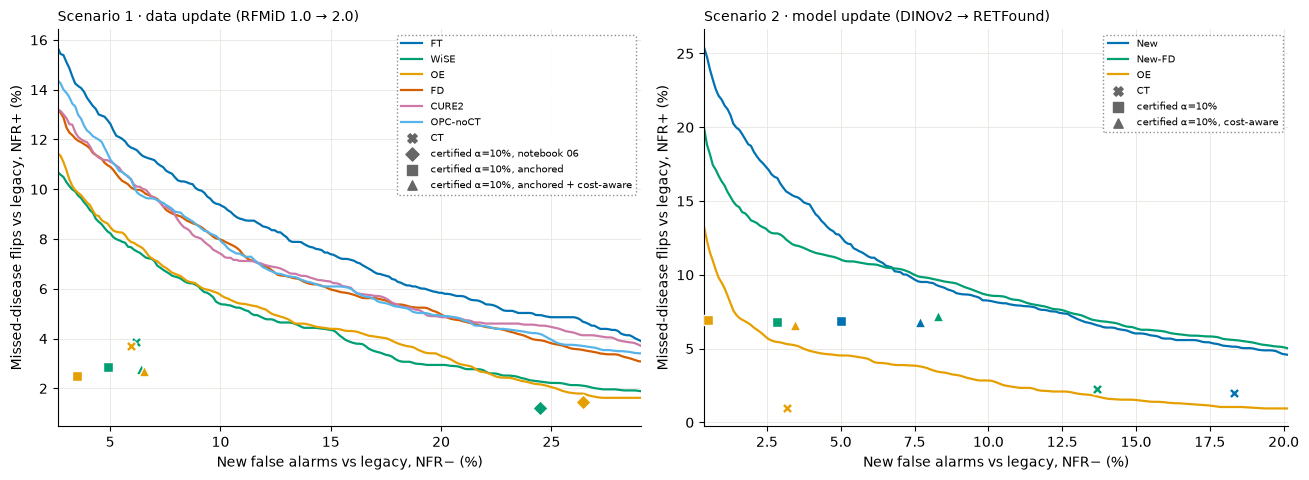

In [14]:
OI = ["#0072B2", "#009E73", "#E69F00", "#D55E00", "#CC79A7", "#56B4E9", "#000000"]   # Okabe-Ito
MARK = {"+CT": ("X", "CT"), "+CRC-A10": ("D", "certified α=10%, notebook 06"), "+CRC-L10": ("s", "certified α=10%, anchored"),
        "+CRCg-L10": ("^", "certified α=10%, anchored + cost-aware"), "+CRC10": ("s", "certified α=10%"),
        "+CRCg10": ("^", "certified α=10%, cost-aware")}

def panel(ax, FS, curves, mean, bases, suffixes, seeds, title):
    colors = dict(zip(curves, OI))
    pts = [f"{b}{s}" for b in bases for s in suffixes if f"{b}{s}" in mean.index]
    xs_all = [mean.loc[p, "NFR-_%"] for p in pts] + [mean.loc[c, "NFR-_%"] for c in curves]
    lo, hi = 0.75 * min(xs_all), 1.1 * max(xs_all)
    xs = np.linspace(lo, hi, 200)
    for c in curves:
        cs = [frontier.curve(FS[(c, s)], GRID) for s in seeds]
        ax.plot(xs, np.mean([[frontier.frontier_at(*cc, v) for v in xs] for cc in cs], axis=0), color=colors[c], lw=1.6, label=c)
    for p in pts:
        b, s = p.split("+")[0], "+" + p.split("+", 1)[1]
        ax.scatter(mean.loc[p, "NFR-_%"], mean.loc[p, "NFR+_%"], marker=MARK[s][0], s=60, color=colors[b], edgecolor="white", lw=1, zorder=5)
    for s in suffixes:
        ax.scatter([], [], marker=MARK[s][0], color="#666666", s=45, label=MARK[s][1])
    ax.set_xlim(lo, hi)
    ax.set_xlabel("New false alarms vs legacy, NFR− (%)")
    ax.set_ylabel("Missed-disease flips vs legacy, NFR+ (%)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(color="#e6e5df", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    leg = ax.legend(fontsize=7.5, loc="best", frameon=True, framealpha=0.95)
    leg.get_frame().set_linestyle(":")
    leg.get_frame().set_edgecolor("#888888")

panels = [p for p in ("s1", "s2") if (p == "s1" and RUN_S1) or (p == "s2" and RUN_S2)]
if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(6.6 * len(panels), 4.9), squeeze=False)
    for ax, p in zip(axes[0], panels):
        if p == "s1":
            panel(ax, FS1, CURVES1, mean1, ["WiSE", "OE"], ["+CT", "+CRC-A10", "+CRC-L10", "+CRCg-L10"], SEEDS,
                  "Scenario 1 · data update (RFMiD 1.0 → 2.0)")
        else:
            panel(ax, FS2, CURVES2, mean2, CURVES2, ["+CT", "+CRC10", "+CRCg10"], SEEDS,
                  "Scenario 2 · model update (DINOv2 → RETFound)")
    fig.tight_layout()
    fig.savefig(RES / ("cert07_frontier_quick.png" if QUICK else "cert07_frontier.png"), dpi=200)
    plt.show()

In [15]:
H = {}
def alpha_of(name):
    return int("".join(ch for ch in name.split("+")[1] if ch.isdigit()))
cert_risk = {}
if RUN_S1:
    best = min([p for p in ("WiSE+CT", "OE+CT") if p in gap1], key=lambda p: gap1[p][0])
    H["H1_plugin_data_update"] = bool(gap1[best][2] < 0)
    H["H1_best"] = {best: gap1[best]}
    cheaper = {m: bool(con1[f"{m}10: anchored-full vs split (CRC-L - CRC-A)"][2] < 0) for m in BASES}
    feas5 = {m: float(1 - valid1.loc[f"{m}+CRC-L5", "infeasible_share"]) for m in BASES}
    H["H4_affordable"] = bool(sum(cheaper[m] and feas5[m] >= 0.8 for m in BASES) >= 2)
    H["H4_detail"] = {m: {"cheaper": cheaper[m], "CRC-L5_feasible_share": round(feas5[m], 3)} for m in BASES}
    H["H5_cost_aware_s1"] = {m: bool(con1[f"{m}10: cost-aware vs CT shape (CRCg-L - CRC-L)"][2] < 0) for m in BASES}
    cert_risk.update({("s1", n): float(mean1.loc[n, "img_risk_%"]) for n in NAMES1 if "+CRC" in n})
if RUN_S2:
    best2 = min([f"{m}+CT" for m in CURVES2], key=lambda p: gap2[p][0])
    H["H6_plugin_model_update"] = bool(gap2[best2][2] < 0)
    H["H6_best"] = {best2: gap2[best2]}
    H["H5_cost_aware_s2"] = {m: bool(con2[f"{m}10: cost-aware vs CT shape (CRCg - CRC)"][2] < 0) for m in CURVES2}
    cert_risk.update({("s2", n): float(mean2.loc[n, "img_risk_%"]) for n in NAMES2 if "+CRC" in n})
H["H2_certificates_hold"] = bool(all(r <= alpha_of(n) + 0.5 for (_, n), r in cert_risk.items())) if cert_risk else None
H["H2_worst"] = (max(cert_risk.items(), key=lambda kv: kv[1] - alpha_of(kv[0][1]))[0][1] if cert_risk else None)

if not (RUN_S1 and RUN_S2):
    verdict = "INCOMPLETE (run both scenarios)"
elif not H["H1_plugin_data_update"]:
    verdict = "STOP"
elif not H["H6_plugin_model_update"]:
    verdict = "REVISE (plug-in holds for the data update only)"
elif not H["H2_certificates_hold"]:
    verdict = "REVISE (a certificate exceeded its alpha)"
else:
    verdict = "GO-FULL" if H["H4_affordable"] else "GO-PLUGIN"

def compact(mean):
    return {n: {"mAP": round(float(r["mAP_all"]), 3), "NFR+": round(float(r["NFR+_%"]), 2), "NFR-": round(float(r["NFR-_%"]), 2),
                "risk": round(float(r["img_risk_%"]), 2), "regr": round(float(r[KEYS[-1]]), 2)} for n, r in mean.iterrows()}
def vcompact(v):
    return {n: {"infeas": round(float(r["infeasible_share"]), 2), "above": round(float(r["runs_above_alpha"]), 2),
                "n_cal": round(float(r["mean_n_cal"]), 1)} for n, r in v.iterrows()}
send = {"notebook": "07_affordable_certificate_two_updates", "quick_mode": QUICK, "seeds": SEEDS, "n_boot": CFG["n_boot"],
        "s1_epochs": CFG["s1_epochs"], "s2_epochs": CFG["s2_epochs"], "shape_set_1.0val": int(KEEP1V.sum())}
if RUN_S1:
    send["s1"] = {"means": compact(mean1), "gap": gap1, "contrasts_NFR-": con1, "validity": vcompact(valid1)}
if RUN_S2:
    send["s2"] = {"means": compact(mean2), "gap": gap2, "contrasts_NFR-": con2, "validity": vcompact(valid2)}
send["hypotheses"], send["verdict"] = H, verdict
(RES / ("cert07_summary_quick.json" if QUICK else "cert07_summary.json")).write_text(json.dumps(send, indent=1, default=str))
print("=" * 30, "SEND THIS BACK", "=" * 30)
print(json.dumps(send, default=str))

============================== SEND THIS BACK ==============================
{"notebook": "07_affordable_certificate_two_updates", "quick_mode": false, "seeds": [0, 1, 2], "n_boot": 300, "s1_epochs": 15, "s2_epochs": 20, "shape_set_1.0val": 631, "s1": {"means": {"CURE2": {"mAP": 0.315, "NFR+": 10.23, "NFR-": 5.86, "risk": 32.33, "regr": 1.33}, "FD": {"mAP": 0.313, "NFR+": 10.32, "NFR-": 5.65, "risk": 32.26, "regr": 1.67}, "FT": {"mAP": 0.346, "NFR+": 11.47, "NFR-": 6.72, "risk": 36.03, "regr": 0.67}, "FT+CRC-A10": {"mAP": 0.346, "NFR+": 1.53, "NFR-": 41.39, "risk": 4.68, "regr": 0.67}, "FT+CRC-A5": {"mAP": 0.346, "NFR+": 0.3, "NFR-": 64.63, "risk": 0.72, "regr": 0.67}, "FT+CRC-L10": {"mAP": 0.346, "NFR+": 2.94, "NFR-": 21.57, "risk": 8.75, "regr": 0.67}, "FT+CRC-L5": {"mAP": 0.346, "NFR+": 1.45, "NFR-": 41.41, "risk": 4.22, "regr": 0.67}, "FT+CRC-LB10": {"mAP": 0.346, "NFR+": 1.92, "NFR-": 35.73, "risk": 5.69, "regr": 0.67}, "FT+CRC-LB5": {"mAP": 0.346, "NFR+": 0.64, "NFR-": 59.31, "ri